#### Artificial Neural

<img style="background-color: white;" src="docs/artifial_neural.png" />



$$
X =
\begin{pmatrix}
x_1^{(1)} & x_2^{(1)} \\
x_1^{(2)} & x_2^{(2)} \\
x_1^{(3)} & x_2^{(3)}
\end{pmatrix}
\qquad
W =
\begin{pmatrix}
w_1 \\
w_2
\end{pmatrix}
$$


$$
Z =
\begin{pmatrix}
x_1^{(1)}w_1 + x_2^{(1)}w_2 + b \\
x_1^{(2)}w_1 + x_2^{(2)}w_2 + b \\
x_1^{(3)}w_1 + x_2^{(3)}w_2 + b
\end{pmatrix}
=
\begin{pmatrix}
z^{(1)} \\
z^{(2)} \\
z^{(3)}
\end{pmatrix}
$$


#### Model

<hr />

$
Z = X \cdot W + b
$

$
A = \frac{1}{1 + e^{-Z}}
$

<hr /><br /> <br />


#### Loss

<hr />

$
L = - \frac{1}{m} \sum_{i = 1}^{m} y_{i} \cdot \log{(A)} + (1 - y_{i}) \cdot \log(1 - A)
$

<hr /><br /> <br />


#### Update

<hr />

$
\frac{\partial L}{\partial W} = \frac{1}{m} X^T \cdot (A - y)
$

$
\frac{\partial L}{\partial b} = \frac{1}{m} \sum (A - y)
$




$
W = W - \alpha \cdot \frac{\partial L}{\partial W}
$



$
b = b - \alpha \cdot \frac{\partial L}{\partial b}
$


<hr />

In [584]:
import numpy as np
import matplotlib.pyplot as plt


In [585]:
class ArtificialNeural:

    _alpha: float
    _n_iterations: int
    _history: np.array
    _weights: np.array
    _biais: float


    def __init__(self, alpha: float = 0.3, n_iterations: int = 100):
        self._alpha = alpha
        self._n_iterations = n_iterations
        self._history = np.array([])

    def initialize_weights(self, lenght: int):
        return np.random.rand(lenght)

    def initialize_biais(self):
        return np.random.random(1)[0]

    def sigmoid(self, weighted_sums: np.array):
        return 1 / (1 + np.exp(- weighted_sums))

    def log_loss(self, activated_outputs: np.array, y_true):
        return -1 / len(y_true) * np.sum(
            y_true * np.log(activated_outputs)
            + (1 - y_true) * np.log(1 - activated_outputs)
        )

    def update_weigths(self, X: np.array, weights: np.array, activated_outputs: np.array, y_true):
        weights = weights - self._alpha * (1 / len(y_true)) * X.T @ (activated_outputs - y_true)
        return weights

    def update_biais(self, X: np.array, biais: np.array, activated_outputs: np.array, y_true):
        biais = biais - self._alpha * (1 / len(y_true)) * np.sum((activated_outputs - y_true))
        return biais

    def weighted_sums(self, X: np.array, weights: np.array, biais: float):
        return biais + X @ weights

    def fit(self, X: np.array, y_true: np.array):

        # 1. Initialization
        self._weights = self.initialize_weights(lenght=np.array(X).shape[1])
        self._biais = self.initialize_biais()

        for i in range(self._n_iterations):

            # 2. Compute Z
            weighted_sums = self.weighted_sums(X, weights=self._weights, biais=self._biais)

            # 3. Compute A
            activated_outputs = self.sigmoid(weighted_sums=weighted_sums)

            # Compute loss
            loss = self.log_loss(activated_outputs=activated_outputs, y_true=y_true)
            self._history = np.append(self._history, loss)

            # 4. Update W & b
            self._weights = self.update_weigths(X, weights=self._weights, activated_outputs=activated_outputs, y_true=y_true)
            self._biais = self.update_biais(X, biais=self._biais, activated_outputs=activated_outputs, y_true=y_true)

    def predict_proba(self, X: np.array):
        weighted_sums = self.weighted_sums(X, weights=self._weights, biais=self._biais)
        activated_outputs = self.sigmoid(weighted_sums=weighted_sums)
        return activated_outputs

    def predict(self, X: np.array): 
        return self.predict_proba(X) >= 0.5


    def plot_loss_history(self):
        plt.figure()
        plt.plot(self._history)

        plt.xlabel('Iterations')
        plt.ylabel('Loss')
        plt.title('Loss over iterations')
        # plt.grid(True)

        plt.show()





In [586]:
# Dataset
n_samples, n_features = 100, 5
X = np.random.random((n_samples, n_features))
y = np.random.randint(low=0, high=2, size=n_samples)

In [587]:
# Train

model = ArtificialNeural(alpha=0.3, n_iterations=100)
model.fit(X, y)

In [588]:
accuracy = np.mean(model.predict(X) == y)
print(f'Accuracy : {accuracy * 100:.2f} %')

Accuracy : 64.00 %


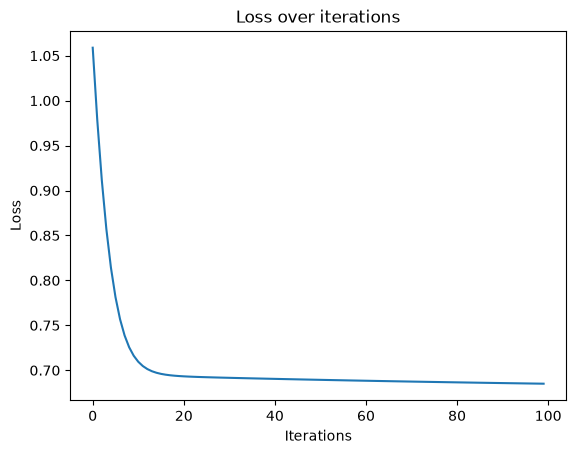

In [589]:
model.plot_loss_history()